# Does the own-data recipe work for a shop unlike Walmart? (Online Retail II)

[`PortableFeatures_CA1Foods.ipynb`](PortableFeatures_CA1Foods.ipynb) showed that the Stage 3 recipe on the `portable-v1` schema works without M5-specific inputs, and estimated how much history a business needs. But every simulated shop there was a random sample of **Walmart CA_1 food products**. A real user of the app might sell something quite different.

This notebook repeats that experiment on a shop that has nothing to do with Walmart: the **UCI Online Retail II** dataset, two years (December 2009 to December 2011) of real transactions from a UK online retailer of gifts and homeware, many of them sold in wholesale packs.

It answers three questions:

1. **Whole shop:** does an own-data model trained on this shop beat "same as last day"?
2. **Small shops:** for 10, 20, 25, 50 and 100 products with 90 to 365 days of history, how often does the gate pass, and by how much does the AI win? How does that compare with the Walmart samples?
3. **Robustness:** do the answers change if the test window avoids the Christmas peak?

Nothing is tuned for this data. Each run calls the same `own_data.train_own_data` the ML service uses, with the eligibility rules switched off so that every size can be tried.

**Data:** Chen, D. (2012). *Online Retail II* [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5CG6D (CC BY 4.0). Download `online_retail_ii.zip` from https://archive.ics.uci.edu/dataset/502/online+retail+ii and unzip it into `data/raw/online_retail_ii/` (git-ignored). Reading the workbook needs `openpyxl`.

In [1]:
from pathlib import Path
import sys
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

projectRoot = Path.cwd().resolve()
while not (projectRoot / "mlengine").is_dir() and projectRoot != projectRoot.parent:
    projectRoot = projectRoot.parent
sys.path.insert(0, str(projectRoot))
figuresDir = projectRoot / "reports" / "figures"
tablesDir = projectRoot / "reports" / "tables"
figuresDir.mkdir(parents=True, exist_ok=True)
tablesDir.mkdir(parents=True, exist_ok=True)

warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.float_format", lambda value: f"{value:,.3f}")
plt.rcParams["figure.figsize"] = (11, 5)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.25

import mlengine
from mlengine.pipelines import own_data
from mlengine.evaluation import demand_class
print(f"mlengine {mlengine.__version__} from {projectRoot}")

mlengine 0.1.0 from C:\Users\lordk\Desktop\SemProject\SemProject_MLEngine


## Data preparation

The dataset is a list of invoice lines, not daily sales, so it has to be turned into what a shop would upload to the app: one row per product per day.

- **Two sheets that overlap.** "Year 2009-2010" and "Year 2010-2011" both contain 1–9 December 2010. The first sheet is cut where the second begins.
- **Not sales:** cancelled invoices (numbers starting with `C`), non-positive quantities or prices, and codes that aren't products (postage, bank charges, Amazon fees, manual adjustments, samples, gift vouchers). Product codes start with a digit; everything else is dropped.
- **Daily totals:** units are summed per product per day (a product can appear on many invoices in a day). The price is the day's median unit price.
- **Closed days.** On days with no transactions at all, the shop was closed. That is nearly every Saturday, plus the Christmas break. These days are **not recorded** (left out), exactly as the app treats a shop's closed days. On days the shop traded, a product with no sales sold **zero**.
- **Big orders stay in.** Some days have very large wholesale orders. They are real sales, and the app keeps spikes too (it flags them but never removes them).

In [2]:
rawDir = projectRoot / "data" / "raw" / "online_retail_ii"
parquetPath = rawDir / "online_retail_II.parquet"
if parquetPath.is_file():
    raw = pd.read_parquet(parquetPath)
else:
    text = {"Invoice": str, "StockCode": str, "Description": str, "Country": str}
    raw = pd.concat(pd.read_excel(rawDir / "online_retail_II.xlsx", sheet_name=None, dtype=text).values(),
                    ignore_index=True)
    raw.to_parquet(parquetPath, index=False)
raw["InvoiceDate"] = pd.to_datetime(raw["InvoiceDate"])

# The second sheet starts where the dates jump back (from 9 Dec 2010 to 1 Dec 2010).
dates = raw["InvoiceDate"].to_numpy()
secondSheet = int(np.argmax(dates[1:] < dates[:-1] - np.timedelta64(2, "D"))) + 1
secondStart = raw["InvoiceDate"].iloc[secondSheet]
first = raw.iloc[:secondSheet]
raw = pd.concat([first[first["InvoiceDate"] < secondStart], raw.iloc[secondSheet:]], ignore_index=True)
print(f"Second sheet starts {secondStart:%Y-%m-%d}; invoice lines kept: {len(raw):,}")

sales = raw[~raw["Invoice"].str.startswith("C") & (raw["Quantity"] > 0) & (raw["Price"] > 0)]
sales = sales[sales["StockCode"].str[0].str.isdigit()].assign(date=lambda f: f["InvoiceDate"].dt.normalize())
daily = (sales.groupby(["StockCode", "date"])
         .agg(units=("Quantity", "sum"), price=("Price", "median")).reset_index())
tradingDays = pd.DatetimeIndex(sorted(daily["date"].unique()))
allDays = pd.date_range(tradingDays.min(), tradingDays.max(), freq="D")
closedDays = allDays.difference(tradingDays)
print(f"{daily['StockCode'].nunique():,} products, {len(daily):,} product-days with sales, "
      f"{tradingDays.min():%Y-%m-%d} to {tradingDays.max():%Y-%m-%d}")
print(f"{len(allDays)} days: {len(tradingDays)} trading, {len(closedDays)} closed "
      f"({(closedDays.dayofweek == 5).sum()} of them Saturdays)")
print("Units per product-day with a sale:",
      daily["units"].quantile([0.5, 0.9, 0.99]).round(0).to_dict(), "max", int(daily["units"].max()))

Second sheet starts 2010-12-01; invoice lines kept: 1,044,848


4,878 products, 531,049 product-days with sales, 2009-12-01 to 2011-12-09
739 days: 604 trading, 135 closed (104 of them Saturdays)
Units per product-day with a sale: {0.5: 6.0, 0.9: 44.0, 0.99: 222.0} max 80995


In [3]:
NO_RULES = {"minProducts": 1, "minHistoryDaysPerProduct": 1, "minStoreHistoryDays": 1, "minObservedProductDays": 1}


def productPool(end, nDays):
    """Products the shop carried through the window: sold in its first 28 days and in its last 28 days."""
    start = end - pd.Timedelta(days=nDays - 1)
    def soldBetween(a, b):
        return set(daily.loc[daily["date"].between(a, b), "StockCode"])
    return sorted(soldBetween(start, start + pd.Timedelta(days=27)) & soldBetween(end - pd.Timedelta(days=27), end))


def shopHistory(products, end, nDays):
    """What the shop would upload: one row per product per trading day, zeros where the product didn't sell."""
    days = pd.date_range(end - pd.Timedelta(days=nDays - 1), end, freq="D").intersection(tradingDays)
    grid = pd.MultiIndex.from_product([products, days], names=["StockCode", "date"]).to_frame(index=False)
    rows = grid.merge(daily, on=["StockCode", "date"], how="left")
    return pd.DataFrame({"store_id": "UK", "product_id": rows["StockCode"], "date": rows["date"],
                         "units_sold": rows["units"].fillna(0.0), "unit_price": rows["price"]})


def summarise(result):
    row = {"status": result["status"]}
    if "backtest" in result:
        bt = result["backtest"]
        row.update(ai_rmse=bt["ai"]["rmse"], naive_rmse=bt["naive_last_value"]["rmse"],
                   ai_mae=bt["ai"]["mae"], naive_mae=bt["naive_last_value"]["mae"],
                   gate=result["gate"]["passed"])
        row["rmse_vs_naive"] = 1 - row["ai_rmse"] / row["naive_rmse"]
        row["mae_vs_naive"] = 1 - row["ai_mae"] / row["naive_mae"]
    return row


lastDay = tradingDays.max()

## How different is this shop from Walmart CA_1 FOODS?

The Syntetos–Boylan demand classes from the app (over each product's last 365 days), for the products this shop carried through its final year, next to the Walmart store the model was built on.

In [4]:
yearPool = productPool(lastDay, 365)
yearHistory = shopHistory(yearPool, lastDay, 365)
wide = yearHistory.pivot(index="product_id", columns="date", values="units_sold")
wide = wide.reindex(columns=pd.date_range(wide.columns.min(), wide.columns.max(), freq="D"))
classes = pd.Series([demand_class.classify(row)["class"] for row in wide.to_numpy()]).value_counts()
order = ["SMOOTH", "ERRATIC", "INTERMITTENT", "LUMPY", "INSUFFICIENT_DATA"]
walmart = pd.Series({"SMOOTH": 221, "ERRATIC": 37, "INTERMITTENT": 925, "LUMPY": 249})
mix = pd.DataFrame({
    "Online Retail II (share)": (classes / classes.sum()).reindex(order),
    "Walmart CA_1 FOODS (share)": (walmart / walmart.sum()).reindex(order),
}).dropna(how="all")
print(f"{len(yearPool):,} products carried through the last year")
display((100 * mix).round(1))
perDay = yearHistory.groupby("product_id")["units_sold"].mean()
print(f"Average units per trading day per product: median {perDay.median():.1f}, 90th percentile {perDay.quantile(0.9):.1f}")

2,008 products carried through the last year


,Online Retail II (share),Walmart CA_1 FOODS (share)
SMOOTH,NaN,15.400
ERRATIC,7.200,2.600
INTERMITTENT,5.800,64.600
LUMPY,86.300,17.400
INSUFFICIENT_DATA,0.700,NaN


Average units per trading day per product: median 2.7, 90th percentile 16.5


## 1. The whole shop

Every product carried through the last year (365 days, ending 9 December 2011), through the own-data pipeline with UK public holidays. As in production, the backtest is the last 28 days and validation the 28 days before.

In [5]:
started = time.time()
wholeShop = own_data.train_own_data(yearHistory, "online-retail", "GB", None, rules=NO_RULES, register=False)
print(f"{time.time() - started:.0f} s, status {wholeShop['status']}, backtest window {wholeShop['backtest']['window']}")
display(pd.DataFrame({name: wholeShop["backtest"][key] for name, key in
                      [("AI (own-data model)", "ai"), ("Same as last day", "naive_last_value"),
                       ("Same weekday last week", "seasonal_naive_7")]}).T[["rmse", "mae", "wape", "n"]])
row = summarise(wholeShop)
print(f"AI vs same as last day: RMSE {100 * row['rmse_vs_naive']:.1f}% lower, MAE {100 * row['mae_vs_naive']:.1f}% lower")

21 s, status GATE_PASSED, backtest window {'startDate': '2011-11-12', 'endDate': '2011-12-09'}


,rmse,mae,wape,n
AI (own-data model),36.259,10.164,0.935,"40,160.000"
Same as last day,49.076,12.515,1.151,"40,160.000"
Same weekday last week,46.427,12.411,1.142,"40,160.000"


AI vs same as last day: RMSE 26.1% lower, MAE 18.8% lower


## 2. Simulated smaller shops

As in the Walmart notebook: for each number of products and length of history (ending on the last day of data), draw products at random from the ones the shop carried through that window, and train. Five seeds per cell instead of three, because 20-product shops are the case we most want to understand. The gate is the production one: the AI must beat "same as last day" on **both** RMSE and MAE.

In [6]:
productCounts = [10, 20, 25, 50, 100]
historyLengths = [90, 120, 180, 365]
seeds = [0, 1, 2, 3, 4]


def simulate(end, label):
    runs = []
    started = time.time()
    for nDays in historyLengths:
        pool = productPool(end, nDays)
        for nProducts in productCounts:
            for seed in seeds:
                chosen = list(np.random.default_rng(seed).choice(pool, nProducts, replace=False))
                history = shopHistory(chosen, end, nDays)
                result = own_data.train_own_data(history, "sim", "GB", None, rules=NO_RULES, register=False)
                runs.append({"scenario": label, "products": nProducts, "history_days": nDays, "seed": seed,
                             "product_days": int(len(history)), **summarise(result)})
    print(f"{label}: {len(runs)} runs in {time.time() - started:.0f} s")
    return pd.DataFrame(runs)


def report(simulation):
    trained = simulation[simulation["status"] != "NOT_ELIGIBLE"]
    passRate = trained.pivot_table(index="products", columns="history_days", values="gate", aggfunc="mean")
    gain = trained.pivot_table(index="products", columns="history_days", values="rmse_vs_naive", aggfunc="median")
    failed = trained[~trained["gate"].astype(bool)]
    print("Share of runs that passed the gate")
    display(passRate)
    print("Median RMSE improvement over same as last day (%)")
    display((100 * gain).round(1))
    print(f"Failures: {len(failed)} of {len(trained)}. Lost on RMSE: {(failed['ai_rmse'] >= failed['naive_rmse']).sum()}, "
          f"lost on MAE only: {((failed['ai_rmse'] < failed['naive_rmse']) & (failed['ai_mae'] >= failed['naive_mae'])).sum()}")
    notTrained = simulation[simulation["status"] == "NOT_ELIGIBLE"]
    if len(notTrained):
        print(f"Not trainable (windows too short after closed days): {len(notTrained)} runs")
    return passRate, gain


december = simulate(lastDay, "ends 9 Dec 2011")
decemberPass, decemberGain = report(december)

ends 9 Dec 2011: 100 runs in 305 s
Share of runs that passed the gate


history_days,90,120,180,365
products,,,,
10,1.000,0.800,0.800,0.800
20,1.000,0.800,0.800,0.800
25,1.000,1.000,1.000,1.000
50,1.000,1.000,1.000,1.000
100,1.000,1.000,1.000,1.000


Median RMSE improvement over same as last day (%)


history_days,90,120,180,365
products,,,,
10,27.100,16.700,28.500,17.300
20,22.900,27.100,12.800,19.200
25,27.800,27.400,17.800,15.400
50,24.700,22.300,22.200,22.700
100,18.200,21.100,21.400,28.300


Failures: 6 of 100. Lost on RMSE: 3, lost on MAE only: 3


### Next to the Walmart samples

Pass rates from [`PortableFeatures_CA1Foods.ipynb`](PortableFeatures_CA1Foods.ipynb) (3 seeds, no 20-product row) beside this shop's.

Walmart CA_1 FOODS                      Online Retail II          \
                        90      120     180  365              90      120   
products                                                                    
10                   33.000  33.000 100.000  100          100.000  80.000   
25                   67.000  67.000  67.000  100          100.000 100.000   
50                  100.000 100.000 100.000  100          100.000 100.000   
100                 100.000 100.000 100.000  100          100.000 100.000   

                          
             180     365  
products                  
10        80.000  80.000  
25       100.000 100.000  
50       100.000 100.000  
100      100.000 100.000

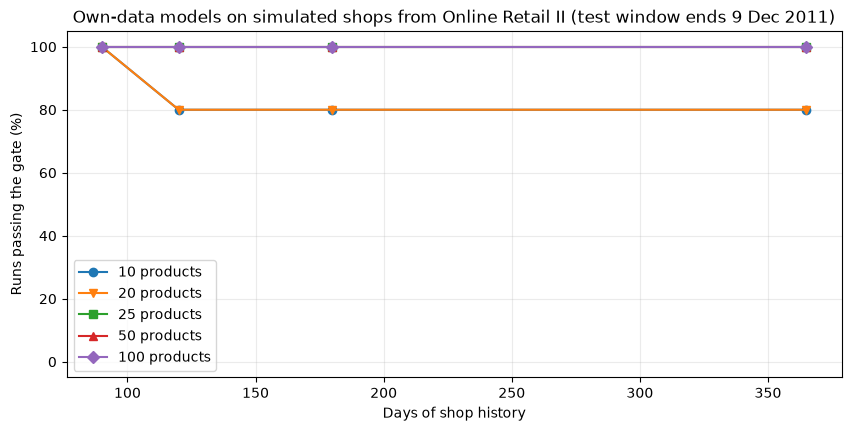

In [7]:
walmartPass = pd.DataFrame({90: [1/3, 2/3, 1, 1], 120: [1/3, 2/3, 1, 1], 180: [1, 2/3, 1, 1], 365: [1, 1, 1, 1]},
                           index=pd.Index([10, 25, 50, 100], name="products"))
side = pd.concat({"Walmart CA_1 FOODS": walmartPass, "Online Retail II": decemberPass.loc[[10, 25, 50, 100]]}, axis=1)
display((100 * side).round(0))

figure, axis = plt.subplots(figsize=(10, 4.5))
markers = {10: "o", 20: "v", 25: "s", 50: "^", 100: "D"}
for nProducts in productCounts:
    axis.plot(historyLengths, 100 * decemberPass.loc[nProducts].to_numpy(), marker=markers[nProducts],
              label=f"{nProducts} products")
axis.set_xlabel("Days of shop history")
axis.set_ylabel("Runs passing the gate (%)")
axis.set_ylim(-5, 105)
axis.set_title("Own-data models on simulated shops from Online Retail II (test window ends 9 Dec 2011)")
axis.legend()
figure.savefig(figuresDir / "portable_online_retail_pass_rate.png", dpi=120, bbox_inches="tight")
plt.show()

## 3. Robustness: a test window without the Christmas rush

The last 28 days of the data (12 November to 9 December 2011) are this shop's busiest weeks, so the test window is unusual. The same simulation is repeated with the history ending on **30 September 2011**, so the test covers September.

In [8]:
september = simulate(pd.Timestamp("2011-09-30"), "ends 30 Sep 2011")
septemberPass, septemberGain = report(september)
pd.concat([december, september]).to_csv(tablesDir / "portable_online_retail_simulation.csv", index=False)

ends 30 Sep 2011: 100 runs in 302 s
Share of runs that passed the gate


history_days,90,120,180,365
products,,,,
10,1.000,0.600,0.600,0.800
20,1.000,1.000,1.000,0.800
25,1.000,1.000,0.800,1.000
50,1.000,1.000,1.000,1.000
100,1.000,1.000,1.000,1.000


Median RMSE improvement over same as last day (%)


history_days,90,120,180,365
products,,,,
10,29.500,16.900,24.800,29.100
20,28.900,25.300,26.200,31.400
25,28.400,29.300,27.800,29.000
50,28.900,26.800,27.700,29.800
100,28.600,27.400,24.200,28.200


Failures: 7 of 100. Lost on RMSE: 2, lost on MAE only: 5


## Conclusions

**1. The recipe works on a shop that has nothing in common with Walmart.** This shop sells UK gifts and homeware, often in wholesale packs, is closed on Saturdays, and 86% of its products are "lumpy" (irregular and unpredictable), against 17% at Walmart CA_1 FOODS. Trained on its own last year (2,008 products), the own-data model passed the gate: RMSE 36.3 against 49.1 for "same as last day" (**26% lower**), MAE 10.2 against 12.5 (19% lower). That is the same relative gain as on Walmart (26% RMSE). Nothing was tuned for this data.

**2. Small shops pass the gate about as often as Walmart samples did, or more.** Across 400 runs (5 random draws per cell, two different test windows):

| Products | Pass rate, test ends 9 Dec 2011 | Pass rate, test ends 30 Sep 2011 | Median RMSE gain when trained |
| --- | --- | --- | --- |
| 10 | 85% | 75% | 17–30% |
| **20** | **85%** | **95%** | 13–31% |
| 25 | 100% | 95% | 15–29% |
| 50 and 100 | 100% | 100% | 18–30% |

Failures were split between RMSE and MAE (5 lost on RMSE, 8 on MAE only), unlike Walmart, where every failure was on MAE. Moving the test window away from the Christmas rush changed little.

**3. History length mattered less than expected.** Even 90 days passed the gate in every run here, where Walmart samples with 10–25 products and 90 days passed in only 1–2 of 3. A likely reason is that this shop's "same as last day" is a weak forecast for lumpy, wholesale-sized orders, so it is easier to beat. A 28-day backtest on 20 products is also small, so single runs are noisy; read the pass *rates*, not individual cells.

**4. "Beats the simple forecast" is not the same as "accurate".** The whole-shop model's WAPE is 94%: its total miss is almost as large as total sales, against 61% on Walmart. For lumpy demand, day-level forecasts of individual products are hard for any method. The AI is still the better choice than "same as last day", which misses by 115%, and the gate exists exactly to make that comparison. But a business owner should read these numbers as rough guides, not commitments. Weekly totals per product, or forecasts for groups of products, would be steadier.

**What this means for the app**

- The answer to "can it work on a 20-product shop with unrelated products?" is **yes, most of the time**: 36 of 40 twenty-product runs passed. When it doesn't, the gate keeps the shop on the simple forecast, as designed.
- The current eligibility rules (120 days and 4,500 product-days) are **conservative** for a shop like this one. A 20-product shop only reaches 4,500 product-days after 7–8 months, yet 20 products with 90–120 days (about 1,550–2,040 product-days) passed here. Lowering the thresholds would let small shops get AI sooner. That is a trade-off to decide with more evidence: two datasets is still a small sample, and the gate is the real safeguard either way.

**Limits of this experiment.** One more shop, not many. Products were drawn from those the shop carried through the whole window (a stable catalogue), which is kinder than a shop with many short-lived products. The shop's closed days were known from the data; a real owner has to tell the app about them. Large wholesale orders were kept as real sales, as the app does.